# CRM-Style Customer Case Tracker

**Skills shown:** CRM-style case logging, prioritisation, SLA tracking, escalation, ownership from receipt to closure, Excel / SQL / Python / Power BI-ready output.

This notebook builds a case tracker that:

- logs each customer request from email, chat, phone and web form with an owner, status and resolution note
- assigns a priority (P1 to P4) and the SLA timers that go with it
- applies an escalation matrix so each case has a clear owner and next step
- reports SLA performance and open cases that are past due

> **About the data:** the cases below are **simulated** (fixed random seed), because real customer data cannot be shared. They are designed to behave like a small service desk, so the tracker logic and charts can be demonstrated. The numbers illustrate the method and are not real company results.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)
os.makedirs('data', exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREEN, RED, AMBER, GREY = '#1F3A5F', '#4C9F70', '#C0392B', '#E0A030', '#8A94A0'

rng = np.random.default_rng(42)
N = 1500
SNAPSHOT = pd.Timestamp('2026-10-31 23:59')   # the date the tracker is "reported" on
START = SNAPSHOT - pd.Timedelta(days=90)

## 1. SLA rules and escalation matrix

Priority decides how fast we must respond and resolve. The escalation matrix says who owns the case at L1 and L2, and when it must be passed on.

In [2]:
SLA = pd.DataFrame({
    'priority': ['P1', 'P2', 'P3', 'P4'],
    'meaning': ['Service down / many customers affected', 'Major issue, no workaround',
                'Standard issue, workaround exists', 'Question or minor request'],
    'first_response_hours': [0.5, 1, 4, 8],
    'resolution_hours': [4, 8, 24, 48],
}).set_index('priority')

ESCALATION_MATRIX = pd.DataFrame({
    'priority': ['P1', 'P2', 'P3', 'P4'],
    'L1 owner': ['Senior agent on shift'] * 2 + ['Assigned agent'] * 2,
    'Escalate to L2 when': ['Immediately', 'No fix within 2 hours', 'No fix within 12 hours', 'No fix within 24 hours'],
    'L2 owner': ['Team lead + technical team', 'Technical team', 'Technical team', 'Team lead'],
    'Customer update every': ['1 hour', '2 hours', '8 hours', '24 hours'],
}).set_index('priority')

ESCALATION_MATRIX

,L1 owner,Escalate to L2 when,L2 owner,Customer update every
priority,,,,
P1,Senior agent on shift,Immediately,Team lead + technical team,1 hour
P2,Senior agent on shift,No fix within 2 hours,Technical team,2 hours
P3,Assigned agent,No fix within 12 hours,Technical team,8 hours
P4,Assigned agent,No fix within 24 hours,Team lead,24 hours


## 2. Log the cases

Each record carries the fields a CRM case would: case ID, created time, channel, category, priority, owner, level, status, response and resolution times and a resolution note.

In [3]:
channels = ['Email', 'Chat', 'Phone', 'Web form']
categories = ['Billing', 'Order / Delivery', 'Technical issue', 'Account access', 'Refund', 'General enquiry']
priorities = ['P1', 'P2', 'P3', 'P4']
agents = [f'Agent_{i:02d}' for i in range(1, 9)]
notes = {
    'Billing': 'Corrected invoice and confirmed with customer',
    'Order / Delivery': 'Located shipment and shared tracking update',
    'Technical issue': 'Applied fix following troubleshooting guide',
    'Account access': 'Reset credentials and verified login',
    'Refund': 'Refund processed and customer informed',
    'General enquiry': 'Provided information and closed',
}
channel_speed = {'Email': 1.15, 'Chat': 0.9, 'Phone': 0.8, 'Web form': 1.2}
esc_prob = {'P1': 0.50, 'P2': 0.30, 'P3': 0.12, 'P4': 0.05}

cases = pd.DataFrame({
    'created_at': START + pd.to_timedelta(rng.uniform(0, 90 * 24 * 3600, N), unit='s'),
    'channel': rng.choice(channels, N, p=[0.38, 0.30, 0.27, 0.05]),
    'category': rng.choice(categories, N, p=[0.18, 0.25, 0.20, 0.12, 0.15, 0.10]),
    'priority': rng.choice(priorities, N, p=[0.05, 0.20, 0.45, 0.30]),
    'owner': rng.choice(agents, N),
}).sort_values('created_at').reset_index(drop=True)
cases.insert(0, 'case_id', [f'CS-{i:05d}' for i in range(1, N + 1)])

sla_res = cases['priority'].map(SLA['resolution_hours'])
sla_fr = cases['priority'].map(SLA['first_response_hours'])
speed = cases['channel'].map(channel_speed)

cases['escalated'] = rng.random(N) < cases['priority'].map(esc_prob)
cases['level'] = np.where(cases['escalated'], 'L2', 'L1')
# resolution time: lognormal around ~40% of the SLA; escalated cases take longer
cases['resolution_hours'] = (rng.lognormal(np.log(0.4), 0.6, N) * sla_res * speed
                             * np.where(cases['escalated'], 1.4, 1.0)).round(2)
cases['first_response_hours'] = (rng.lognormal(np.log(0.3), 0.7, N) * sla_fr).round(2)
cases['resolution_due'] = cases['created_at'] + pd.to_timedelta(sla_res, unit='h')

resolved_at = cases['created_at'] + pd.to_timedelta(cases['resolution_hours'], unit='h')
still_open = (resolved_at > SNAPSHOT) | (rng.random(N) < 0.04)
cases['status'] = np.where(still_open, np.where(cases['escalated'], 'Escalated - L2', 'Open'), 'Closed')
cases.loc[still_open, 'resolution_hours'] = np.nan
cases['resolution_note'] = np.where(still_open, '', cases['category'].map(notes))
cases['response_sla_met'] = cases['first_response_hours'] <= sla_fr
cases['age_hours'] = np.where(still_open, (SNAPSHOT - cases['created_at']).dt.total_seconds() / 3600, np.nan)
cases['resolution_sla_met'] = np.where(still_open, np.nan, cases['resolution_hours'] <= sla_res)

cases.head(8)

,case_id,created_at,channel,category,priority,owner,escalated,level,resolution_hours,first_response_hours,resolution_due,status,resolution_note,response_sla_met,age_hours,resolution_sla_met
0,CS-00001,2026-08-03 01:06:13.754632526,Chat,Billing,P4,Agent_08,True,L2,20.02,1.79,2026-08-05 01:06:13.754632526,Closed,Corrected invoice and confirmed with customer,True,NaN,1.0
1,CS-00002,2026-08-03 02:17:20.608016883,Chat,Order / Delivery,P4,Agent_04,False,L1,18.52,3.62,2026-08-05 02:17:20.608016883,Closed,Located shipment and shared tracking update,True,NaN,1.0
2,CS-00003,2026-08-03 02:38:48.294092598,Email,Technical issue,P3,Agent_01,False,L1,NaN,0.74,2026-08-04 02:38:48.294092598,Open,,True,2157.336585,NaN
3,CS-00004,2026-08-03 03:34:13.662879249,Email,Order / Delivery,P2,Agent_04,False,L1,7.85,0.27,2026-08-03 11:34:13.662879249,Closed,Located shipment and shared tracking update,True,NaN,1.0
4,CS-00005,2026-08-03 04:58:13.015634506,Email,Technical issue,P3,Agent_03,False,L1,27.51,0.90,2026-08-04 04:58:13.015634506,Closed,Applied fix following troubleshooting guide,True,NaN,0.0
5,CS-00006,2026-08-03 08:38:23.134406448,Web form,Technical issue,P3,Agent_01,True,L2,36.91,0.19,2026-08-04 08:38:23.134406448,Closed,Applied fix following troubleshooting guide,True,NaN,0.0
6,CS-00007,2026-08-03 09:42:12.971530789,Email,Order / Delivery,P4,Agent_03,False,L1,17.28,2.62,2026-08-05 09:42:12.971530789,Closed,Located shipment and shared tracking update,True,NaN,1.0
7,CS-00008,2026-08-03 09:57:35.779805715,Email,Refund,P4,Agent_05,False,L1,12.46,2.11,2026-08-05 09:57:35.779805715,Closed,Refund processed and customer informed,True,NaN,1.0


In [4]:
cases.to_csv('data/case_tracker_simulated.csv', index=False)
try:
    cases.to_excel('data/case_tracker_simulated.xlsx', index=False)   # opens in Excel / Power BI
    print('Saved data/case_tracker_simulated.csv and .xlsx')
except Exception as e:
    print('Saved CSV only (install openpyxl for Excel output):', e)

Saved data/case_tracker_simulated.csv and .xlsx


## 3. SLA performance summary

In [5]:
closed = cases[cases['status'] == 'Closed']
open_cases = cases[cases['status'] != 'Closed'].copy()
open_cases['past_due'] = SNAPSHOT > open_cases['resolution_due']

kpis = {
    'Total cases logged': len(cases),
    'Closed': len(closed),
    'Open or escalated': len(open_cases),
    'First-response SLA met (%)': round(cases['response_sla_met'].mean() * 100, 1),
    'Resolution SLA met, closed cases (%)': round(closed['resolution_sla_met'].astype(bool).mean() * 100, 1),
    'Average resolution time (hours)': round(closed['resolution_hours'].mean(), 1),
    'Escalation rate (%)': round(cases['escalated'].mean() * 100, 1),
    'Open cases already past SLA due time': int(open_cases['past_due'].sum()),
}
pd.Series(kpis, name='Value').to_frame()

,Value
Total cases logged,1500.0
Closed,1440.0
Open or escalated,60.0
First-response SLA met (%),95.3
"Resolution SLA met, closed cases (%)",92.0
Average resolution time (hours),12.7
Escalation rate (%),14.7
Open cases already past SLA due time,46.0


## 4. Charts

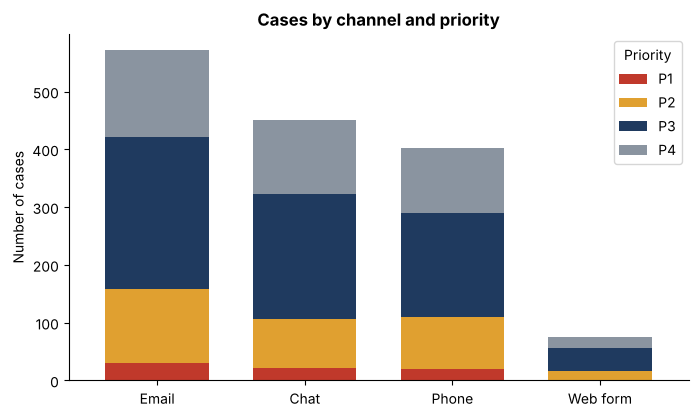

In [6]:
vol = cases.groupby(['channel', 'priority']).size().unstack(fill_value=0).loc[channels]
ax = vol.plot(kind='bar', stacked=True, figsize=(8, 4.5), color=[RED, AMBER, BLUE, GREY], width=0.7)
ax.set_title('Cases by channel and priority', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Number of cases')
plt.xticks(rotation=0)
plt.legend(title='Priority')
plt.savefig('charts/cases_by_channel_priority.png', dpi=130, bbox_inches='tight')
plt.show()

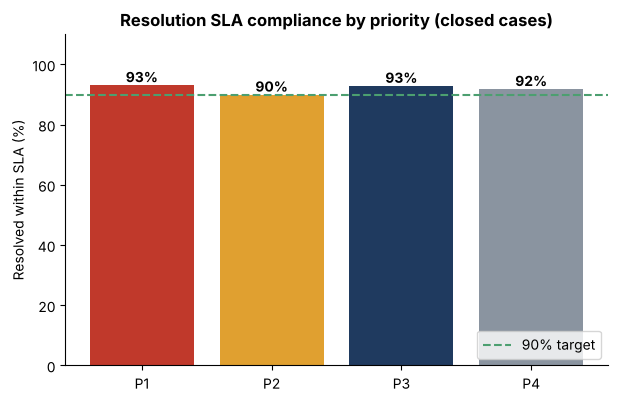

In [7]:
sla_pr = closed.groupby('priority')['resolution_sla_met'].apply(lambda s: s.astype(bool).mean() * 100).reindex(priorities)
fig, ax = plt.subplots(figsize=(7, 4.3))
bars = ax.bar(sla_pr.index, sla_pr.values, color=[RED, AMBER, BLUE, GREY])
for b, v in zip(bars, sla_pr.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')
ax.axhline(90, color=GREEN, ls='--', lw=1.5, label='90% target')
ax.legend(loc='lower right')
ax.set_ylim(0, 110)
ax.set_ylabel('Resolved within SLA (%)')
ax.set_title('Resolution SLA compliance by priority (closed cases)', fontweight='bold')
plt.savefig('charts/sla_compliance_by_priority.png', dpi=130, bbox_inches='tight')
plt.show()

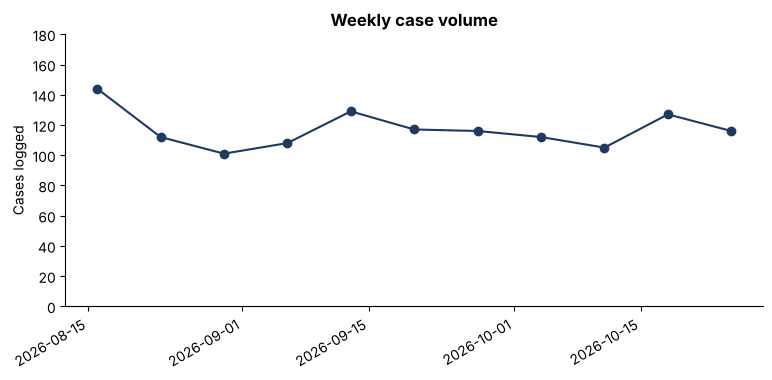

In [8]:
weekly = cases.set_index('created_at').resample('W').size()
weekly = weekly.iloc[1:-1]   # drop the partial first and last weeks
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weekly.index, weekly.values, marker='o', color=BLUE)
ax.set_title('Weekly case volume', fontweight='bold')
ax.set_ylabel('Cases logged')
ax.set_ylim(0, weekly.max() * 1.25)
fig.autofmt_xdate()
plt.savefig('charts/weekly_volume.png', dpi=130, bbox_inches='tight')
plt.show()

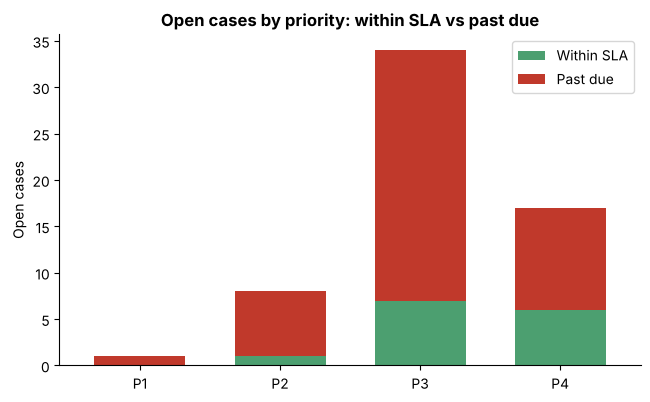

In [9]:
pd_open = (open_cases.groupby(['priority', 'past_due']).size().unstack(fill_value=0)
           .reindex(index=priorities, columns=[False, True], fill_value=0))
ax = pd_open.plot(kind='bar', stacked=True, figsize=(7.5, 4.3), color=[GREEN, RED], width=0.65)
ax.set_title('Open cases by priority: within SLA vs past due', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Open cases')
ax.legend(['Within SLA', 'Past due'])
plt.xticks(rotation=0)
plt.savefig('charts/open_cases_past_due.png', dpi=130, bbox_inches='tight')
plt.show()

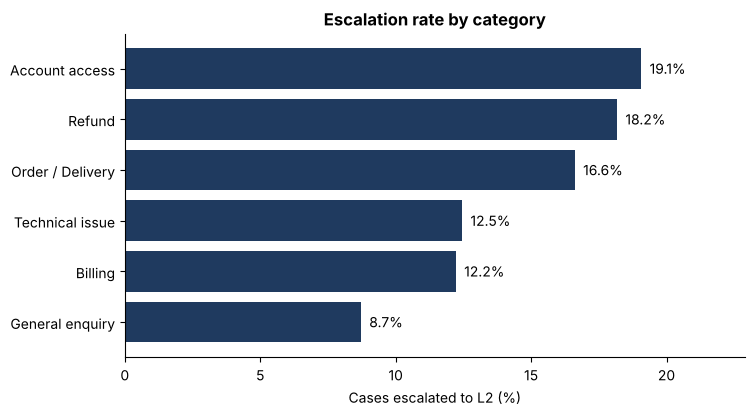

In [10]:
esc = (cases.groupby('category')['escalated'].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(esc.index, esc.values, color=BLUE)
for i, v in enumerate(esc.values):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center')
ax.set_xlabel('Cases escalated to L2 (%)')
ax.set_title('Escalation rate by category', fontweight='bold')
ax.set_xlim(0, esc.max() * 1.2)
plt.savefig('charts/escalation_rate_by_category.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Reading the results

The tracker answers the questions a team lead asks every day: which cases are open, which are about to breach, who owns them and where escalations come from. In a real service desk these records would come from the CRM export, and the same code would run unchanged on that file.

**Next steps for a real deployment:** load the CRM export instead of the simulated data, review the SLA targets with the business, and publish the tables above to a Power BI dashboard for daily monitoring.